# Лабораторная 7. Устойчивый сбор

Вариант 3: HTML и API, отказ одного источника при работающем втором, 404 на части URL. A/B/C выполнены на локальном учебном стенде с одинаковыми 60 сохранёнными записями.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
lab=Path.cwd() if (Path.cwd()/'reports/run_report_A.json').exists() else Path.cwd()/'lab7'
profiles={p:json.loads((lab/f'reports/run_report_{p}.json').read_text(encoding='utf-8')) for p in ('A','B','C')}
table=pd.DataFrame([{'Прогон':p,**{k:r[k] for k in ('requests','records','network_records','duration_s','wire_bytes','not_modified','retries','median_ms','p95_ms','verdict')}} for p,r in profiles.items()])
display(table)
print('C сохраняет 60 записей архива, но не скачивает их заново.')


,Прогон,requests,records,network_records,duration_s,wire_bytes,not_modified,retries,median_ms,p95_ms,verdict
0,A,10,60,60,0.2528,17826,0,0,44.96235,50.865395,green
1,B,10,60,60,2.4317,17826,0,0,40.70660,48.490055,green
2,C,4,60,0,0.6586,0,4,0,32.63100,33.353115,green


C сохраняет 60 записей архива, но не скачивает их заново.


## 1. Снижение нагрузки

Байты — тела HTTP-ответов; заголовки и транспортные накладные расходы не включены. При 304 заголовки продолжают передаваться.

In [2]:
display(pd.DataFrame(json.loads((lab/'reports/load_savings.json').read_text(encoding='utf-8'))))
print('Дополнительное время B против A:',round(profiles['B']['duration_s']-profiles['A']['duration_s'],3),'с')


,mechanism,requests_before,requests_after,bytes_before,bytes_after,saved_percent
0,conditional,10,10,17826,0,100.00
1,gzip,10,10,17826,6159,65.45
2,incremental,10,4,17826,476,97.33


Дополнительное время B против A: 2.179 с


## 2. Структурные логи и графики

,profile,event,host,status,ms,attempt,bytes
0,A,request,127.0.0.2,200.0,38.7203,1,98
1,A,request,127.0.0.1,200.0,54.2363,1,98
2,A,request,127.0.0.1,200.0,29.9446,1,140
3,A,request,127.0.0.2,200.0,45.3607,1,140
4,A,request,127.0.0.2,200.0,44.7632,1,1958
5,A,request,127.0.0.1,200.0,46.7454,1,4614
6,A,request,127.0.0.2,200.0,45.1615,1,1883
7,A,request,127.0.0.1,200.0,31.6980,1,3395
8,A,request,127.0.0.2,200.0,46.0223,1,2006
9,A,request,127.0.0.1,200.0,41.7920,1,3494


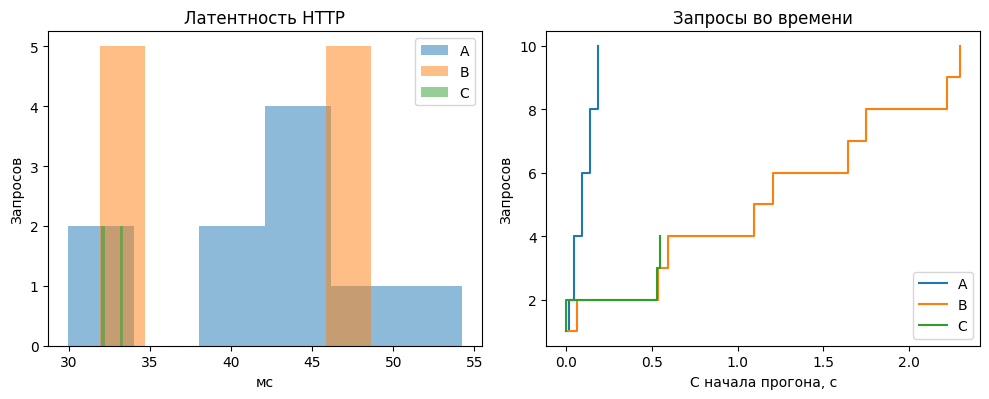

In [3]:
import matplotlib.pyplot as plt
all_logs=[]
for p,r in profiles.items():
    log=pd.read_json(lab/r['log'],lines=True)
    log=log[log['event'].eq('request')].copy()
    log['profile']=p
    log['ts']=pd.to_datetime(log['ts'],utc=True)
    log['elapsed_s']=(log['ts']-log['ts'].min()).dt.total_seconds()
    all_logs.append(log)
logs=pd.concat(all_logs,ignore_index=True)
display(logs[['profile','event','host','status','ms','attempt','bytes']].head(12))
fig,axes=plt.subplots(1,2,figsize=(10,4.1))
for p,group in logs.groupby('profile'):
    axes[0].hist(group['ms'],bins=6,alpha=.5,label=p)
    group=group.sort_values('elapsed_s')
    axes[1].step(group['elapsed_s'],range(1,len(group)+1),where='post',label=p)
axes[0].set(title='Латентность HTTP',xlabel='мс',ylabel='Запросов')
axes[1].set(title='Запросы во времени',xlabel='С начала прогона, с',ylabel='Запросов')
for ax in axes:ax.legend()
fig.tight_layout()
(lab/'figures').mkdir(exist_ok=True)
fig.savefig(lab/'figures/observability.png',dpi=150)
plt.show()


## 3. Изоляция отказа, повторы и предохранитель

In [4]:
faults=json.loads((lab/'reports/scenario_faults.json').read_text(encoding='utf-8'))
print(faults['notes'])
print('Активаций предохранителя:',faults['breaker_activations'])
fault_log=pd.read_json(lab/faults['log'],lines=True)
display(fault_log[fault_log['event'].isin(['retry','circuit_open','skip_open','circuit_half_open','circuit_closed'])][['event','host','status','attempt','delay_s','delay_source']].fillna(''))
print('404-запросы выполняются по одному разу:')
display(fault_log[(fault_log['event']=='request') & (fault_log['status']==404)][['url','attempt','status']])


{'initial_html_failed': True, 'api_continues': True, 'html_recovered': True, 'final_breaker_state': 'closed'}
Активаций предохранителя: 1


,event,host,status,attempt,delay_s,delay_source
1,retry,127.0.0.1,500.0,1,0.197686,full_jitter
3,circuit_open,127.0.0.1,,0,,
4,retry,127.0.0.1,500.0,2,0.349272,full_jitter
5,skip_open,127.0.0.1,,0,,
6,skip_open,127.0.0.1,,0,,
8,circuit_half_open,127.0.0.1,,0,,
10,circuit_closed,127.0.0.1,,0,,
16,retry,127.0.0.2,429.0,1,1.0,Retry-After
19,retry,127.0.0.2,429.0,1,1.019105,Retry-After
22,retry,127.0.0.2,429.0,1,0.105608,full_jitter


404-запросы выполняются по одному разу:


,url,attempt,status
11,http://127.0.0.2:8798/missing-one,1,404.0
13,http://127.0.0.2:8798/missing-two,1,404.0


## 4. Детектор и оповещения

In [5]:
blocked=json.loads((lab/'reports/scenario_blocked.json').read_text(encoding='utf-8'))
print('Заглушка:',blocked['notes'])
print('Итог:',blocked['verdict'],'; процесс возвращает код 2')
display(pd.DataFrame(blocked['alerts']))
display(pd.read_json(lab/blocked['log'],lines=True)[['event','host','status','error']])


Заглушка: {'api_continues': True, 'html_stopped': True}
Итог: red ; процесс возвращает код 2


,metric,value,threshold,reason
0,blocked_domains,1,0,Любая блокировка останавливает сбор домена


,event,host,status,error
0,request,127.0.0.1,200.0,
1,blocked_domain,127.0.0.1,NaN,"status, marker or missing expected records"
2,skip_blocked,127.0.0.1,NaN,
3,request,127.0.0.2,200.0,


## Полные показатели инцидентов и интервалы

Показатели воспроизводимых сбоев отделены от нормального сравнения A/B/C. Интервалы восстановлены по временам начала запросов одного домена.

In [6]:
columns = ['requests','codes','error_share','rate_or_block_share','retries','median_ms','p95_ms','wire_bytes','not_modified','breaker_activations','records','rejected','duration_s','verdict']
display(pd.DataFrame({'faults':faults,'blocked':blocked}).T[columns])
rates=json.loads((lab/'reports/rate_limits.json').read_text(encoding='utf-8'))
display(pd.DataFrame(rates['origins']))
display(pd.DataFrame(json.loads((lab/'reports/robots_review.json').read_text(encoding='utf-8'))))

,requests,codes,error_share,rate_or_block_share,retries,median_ms,p95_ms,wire_bytes,not_modified,breaker_activations,records,rejected,duration_s,verdict
faults,12,"{'500': 2, '200': 5, '404': 2, '429': 3}",0.583333,0.25,5,47.48665,48.373645,12673,0,1,20,0,7.8005,red
blocked,2,{'200': 2},0.0,0.0,0,55.1952,62.31573,2029,0,0,10,0,0.3367,red


,host,requests,intervals,minimum_s,median_s,configured_minimum_s
0,127.0.0.2,5,4,0.533895,0.555635,0.5
1,127.0.0.1,5,4,0.532539,0.548337,0.5


,source,url,status,target,can_fetch,crawl_delay,sitemaps,rules_file,policy
0,openlibrary,https://openlibrary.org/robots.txt,200,https://openlibrary.org/search.json?q=python&l...,False,None,[https://openlibrary.org/static/sitemaps/sitei...,robots_openlibrary.txt,NaN
1,quotes,https://quotes.toscrape.com/robots.txt,404,https://quotes.toscrape.com/page/1/,True,None,None,NaN,robots отсутствует; собственный лимит сохраняется


## 5. Проверка реальных источников и robots.txt

Реальный HTML-ответ проверен отдельно. Search API не обходился при запрете robots.txt; A/B/C используют локальные копии прежних данных.

In [7]:
display(pd.DataFrame(json.loads((lab/'reports/real_probe.json').read_text(encoding='utf-8'))))
print('Правила и результаты проверки сохранены в reports/.')


,url,robots,records,blocked
0,https://quotes.toscrape.com/page/1/,{'url': 'https://quotes.toscrape.com/robots.tx...,10,False
1,https://openlibrary.org/search.json?q=python&l...,"{'url': 'https://openlibrary.org/robots.txt', ...",0,False


Правила и результаты проверки сохранены в reports/.


## 6. n8n

На подмножестве API получены 30 строк. Ветка 429 повторяет запрос, 404 сразу приводит к журналу ошибки и Stop and Error.

In [8]:
nocode=pd.read_csv(lab/'nocode/nocode_result.csv',dtype=str)
print('Строк:',len(nocode),'уникальных ключей:',nocode['business_key'].nunique())
display(nocode.head())
metrics=[dict(scenario=name,**json.loads((lab/'nocode'/name).read_text(encoding='utf-8'))) for name in ('metrics.json','metrics_rate_limit.json','metrics_missing_url.json')]
display(pd.DataFrame(metrics)[['scenario','status','requests','duration_s']])


Строк: 30 уникальных ключей: 30


,business_key,title,source,url
0,api:/works/OL10056472W,Bioinformatics Programming in Python,openlibrary,https://openlibrary.org/works/OL10056472W
1,api:/works/OL1033722W,XML Processing with Python,openlibrary,https://openlibrary.org/works/OL1033722W
2,api:/works/OL10538818W,The life of Python,openlibrary,https://openlibrary.org/works/OL10538818W
3,api:/works/OL106747W,Python scripting for computational science,openlibrary,https://openlibrary.org/works/OL106747W
4,api:/works/OL11791152W,Python for bioinformatics,openlibrary,https://openlibrary.org/works/OL11791152W


,scenario,status,requests,duration_s
0,metrics.json,success,3,2.166
1,metrics_rate_limit.json,success,4,3.222
2,metrics_missing_url.json,error,1,0.992
